# Ragged panels

Real panels rarely hold series of equal length: one product launched last
quarter, another has reported for a decade. A panel like that is **ragged**.
This page covers how `conformalforecast` represents it, what it guarantees,
and where it will stop you.

## Left-NaN padding

A `Series` array is always `(n_series, T)`. Short series are padded with NaN **on
the left**, so every series ends on the same column and column `T-1` means "most
recent" for all of them.

That convention is enforced. An interior gap or a trailing NaN is an error, because
either would silently break the "last column is now" invariant that every method
relies on.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

from conformalforecast import (
    InsufficientCalibrationSamples,
    SplitConformal,
)
from conformalforecast import (
    panel as P,
)
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import coverage_by_series, evaluate

HORIZON, SEASON, ALPHA = 24, 24, 0.1
N_HOLDOUT = 4

df = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
matrix, index = P.long_to_panel(df["y"].to_numpy(), df["unique_id"].to_numpy(), df["ds"].to_numpy())

print("panel      ", matrix.shape)
print("series     ", index.series_ids)
print("lengths    ", index.lengths)
print("NaN cells  ", int(np.isnan(matrix).sum()))

# Hold the tail out before anything is fitted, so the coverage measured at the
# end of this page is measured on data no part of the pipeline has seen.
train_df = df[df["ds"] <= df["ds"].max() - pd.Timedelta(hours=N_HOLDOUT * HORIZON)].reset_index(
    drop=True
)
print("training through", train_df["ds"].max(), f"({N_HOLDOUT * HORIZON} hours held out)")

panel       (8, 672)
series      ('H1', 'H10', 'H100', 'H150', 'H200', 'H300', 'H400', 'H50')
lengths     [672 672 600 576 528 504 672 648]
NaN cells   504
training through 2015-01-24 23:00:00 (96 hours held out)


`long_to_panel` returns the matrix and a `PanelIndex` that remembers how to undo
the pivot: the series ids, each series' length, its offset into the matrix, and
the timestamps. `panel_to_long` uses it to go back, dropping the padding.

In [ ]:
series_ids, timestamps, values = P.panel_to_long(matrix, index)
print(f"{len(values)} non-NaN observations recovered, from {matrix.size} cells")
np.testing.assert_allclose(np.sort(values), np.sort(df["y"].to_numpy()))
print("round trip is lossless")

4872 non-NaN observations recovered, from 5376 cells
round trip is lossless


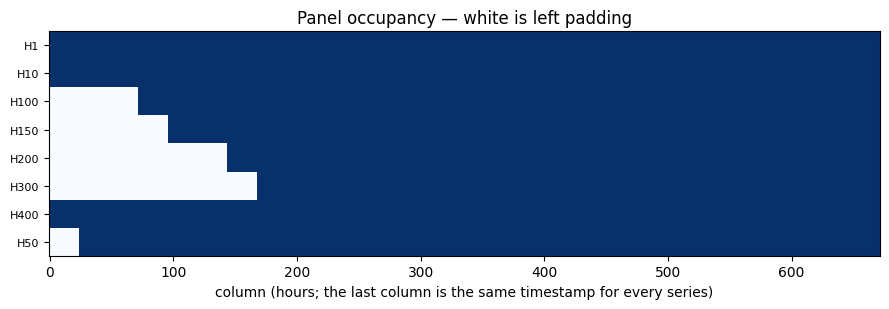

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.2))
observed = ~np.isnan(matrix)
ax.imshow(observed, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(np.arange(len(index.series_ids)))
ax.set_yticklabels(index.series_ids, fontsize=8)
ax.set_xlabel("column (hours; the last column is the same timestamp for every series)")
ax.set_title("Panel occupancy — white is left padding")
fig.tight_layout()

## Methods propagate NaN, they never impute

A NaN in a calibration array means "this window does not exist for this series".
A method carries that through scoring and takes per-`(series, horizon)` quantiles
with NaN-aware order statistics, so a short series is calibrated on its own
windows and nobody else's.

The consequence you can see is `n_calibration_samples_` on the fitted object: an
**effective** count per series, not the number you asked for.

In [ ]:
sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="h", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=HORIZON, freq="h", model_name="SeasonalNaive"
)

fitted = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=30, refit=True)
print("effective windows per series:", fitted.n_calibration_samples_)

effective windows per series: [30 30 30 30 30 30 30 30]


Here every series is long enough that all 30 windows exist, so the counts are
uniform. Ask for more windows than the shortest series can supply and the
arithmetic changes.

## The floor, and the error you get

Every series needs at least `ceil(1 / alpha)` effective windows. Below that the
requested quantile is not attainable from the sample at all, and `fit`
refuses rather than returning something that looks like an interval.

In [ ]:
strict = SplitConformal(alpha=0.01)  # needs 100 windows
try:
    strict.calibrate_cv(forecaster, n_windows=30, refit=True)
except InsufficientCalibrationSamples as error:
    print(type(error).__name__)
    print(error)
    print("offending series indices:", error.series_indices)
    print("names:", [index.series_ids[i] for i in error.series_indices])

InsufficientCalibrationSamples
Series [0, 1, 2, 3, 4, 5, 6, 7] have fewer than ceil(1/alpha) = 100 effective calibration samples for alpha=0.01.
offending series indices: [0, 1, 2, 3, 4, 5, 6, 7]
names: ['H1', 'H10', 'H100', 'H150', 'H200', 'H300', 'H400', 'H50']


`series_indices` is the point of the exception: on a 500-series panel you need to
know *which* ones are short, not merely that something was.

::: {.callout-note}
## `ceil(1/alpha)` is arithmetic, not a heuristic

The conformal quantile is the `k = ceil((1 - alpha)(n + 1))`-th order statistic.
For that index to exist at all you need `n >= 1/alpha - 1`; below it the
interval would have to be unbounded. The package rounds that up to the
`n >= ceil(1/alpha)` the error message quotes, so `alpha = 0.01` genuinely
requires 100 windows. Lowering `alpha` is not free.
:::

## Dense windows vs calendar-aligned cutoffs

`calibrate_cv` has an `aligned` flag, and it decides what axis 1 of the
calibration arrays *means*.

- **`aligned=False`** (the default) — dense per-series windows. Window `k` is "k
  steps before this series' own end". Every series contributes the same number of
  windows, and no NaN is introduced.
- **`aligned=True`** — calendar-aligned cutoffs. Window `k` is the same wall-clock
  cutoff for every series, and a series that did not exist yet gets a NaN cell.

For split conformal the distinction rarely matters: it pools windows and takes a
quantile, and pooling is order-free. For the recency-weighted methods it matters
a great deal — [NexCP](../methods/nexcp.html) reads axis 1 as chronological age and
weights by it, and [SPCI](../methods/spci.html) feeds it to a regressor as a sequence.
Aligning the axis to the calendar makes "age" mean the same thing across series.

In [ ]:
method = SplitConformal(alpha=ALPHA)
dense = method.calibrate_cv(forecaster, n_windows=30, refit=True, aligned=False)
aligned = method.calibrate_cv(forecaster, n_windows=30, refit=True, aligned=True)

print("dense   ", dense.n_calibration_samples_)
print("aligned ", aligned.n_calibration_samples_)

dense    [30 30 30 30 30 30 30 30]
aligned  [30 30 30 30 30 30 30 30]


Identical here, and that is worth understanding rather than glossing over. This
panel was built so every series **ends** on the same timestamp; they differ only
in where they start. The last 30 cutoffs are therefore the same 30 wall-clock
times for all eight series, and every series is long enough to cover them. The
two modes coincide.

They diverge when series end at *different* times, or when a series is too young
to reach the earliest aligned cutoff — then `aligned=True` produces the NaN cells
that the dense mode would have quietly filled with a different series' history.

::: {.callout-warning}
## Nixtla cross-validation has its own length requirement

`aligned` is a `conformalforecast` concept, but the windows come from the
underlying library. statsforecast raises `ValueError: The following series are
too short for the cross validation settings` before either mode is reached if any
series cannot supply `n_windows` cutoffs. Assemble the arrays yourself — with
`panel.cv_frames_to_arrays`, in the panel API reference — if you need windows
the library will not give you.
:::

Which is easy enough to show, since nothing about a retired series is exotic.
Truncate one series' tail and the two modes stop agreeing.


In [ ]:
# Retire one series 48 hours early, so the panel no longer shares an end date.
retired = index.series_ids[0]
last = train_df.loc[train_df["unique_id"] == retired, "ds"].max()
ragged_end_df = train_df[
    (train_df["unique_id"] != retired) | (train_df["ds"] <= last - pd.Timedelta(hours=48))
].reset_index(drop=True)

sf_ragged = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="h", n_jobs=1)
sf_ragged.fit(ragged_end_df)
ragged = StatsForecastAdapter(
    sf=sf_ragged, train_df=ragged_end_df, horizon=HORIZON, freq="h", model_name="SeasonalNaive"
)

dense_preds, _ = ragged.cross_validate(n_windows=10, step_size=1, aligned=False)
aligned_preds, _ = ragged.cross_validate(n_windows=10, step_size=1, aligned=True)

dense_n = method.calibrate_cv(ragged, n_windows=10, aligned=False).n_calibration_samples_
aligned_n = method.calibrate_cv(ragged, n_windows=10, aligned=True).n_calibration_samples_

print(f"{retired} now ends 48h before the other seven\n")
print(f"dense    {dense_preds.shape}   NaN cells {int(np.isnan(dense_preds).sum()):>6}")
print(f"aligned  {aligned_preds.shape}   NaN cells {int(np.isnan(aligned_preds).sum()):>6}")
print("\neffective windows per series")
print("  dense  ", dense_n)
print("  aligned", aligned_n)

H1 now ends 48h before the other seven

dense    (8, 10, 24)   NaN cells      0
aligned  (8, 20, 24)   NaN cells   1920

effective windows per series
  dense   [10 10 10 10 10 10 10 10]
  aligned [10 10 10 10 10 10 10 10]


Both modes still give every series its ten windows — dense compacts them, so
`n_calibration_samples_` is 10 either way. The difference is the axis they sit on.

statsforecast counts cutoffs back from *each series' own* end date, so the retired
series' ten cutoffs are 48 hours earlier than everyone else's and share nothing
with them. Dense mode says "window `k` is k steps before this series' end" and
returns a compact array. Aligned mode has to put every distinct cutoff on the
calendar axis, so it returns a wider, mostly-NaN cube: each series occupies only
the columns it actually reached.

::: {.callout-warning}
## Aligned mode is not free on a panel with many distinct end dates

The calendar axis is the union of every series' cutoffs. When end dates are
spread out, that union grows with the number of series rather than with
`n_windows`, and the cube grows with it. Worse, axis 1 stops meaning
"chronological age", which is exactly what [NexCP](../methods/nexcp.html) and
[SPCI](../methods/spci.html) read it as. Prefer the default `aligned=False` unless
you specifically need calendar comparability.
:::


## Per-series diagnostics

The real payoff of keeping series separate is that you can ask where the interval
is failing.

In [ ]:
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = matrix.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(matrix[:, :end])
    truths.append(matrix[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

report = evaluate(fitted, histories, truths)
per_series = coverage_by_series(report.intervals, report.truths)

print(f"marginal coverage {report.marginal_coverage:.1%}\n")
print(f"{'series':8s}{'length':>8s}{'coverage':>10s}{'mean width':>12s}")
widths = (report.intervals[..., 1] - report.intervals[..., 0]).mean(axis=(1, 2))
for i, name in enumerate(index.series_ids):
    print(f"{name:8s}{index.lengths[i]:8d}{per_series[i]:9.1%}{widths[i]:12.1f}")

marginal coverage 85.2%

series    length  coverage  mean width
H1           672    63.5%        88.1
H10          672    95.8%        63.8
H100         600    95.8%       705.9
H150         576    81.2%       180.3
H200         528    83.3%         0.3
H300         504    77.1%         0.4
H400         672    84.4%       227.7
H50          648   100.0%      6922.8


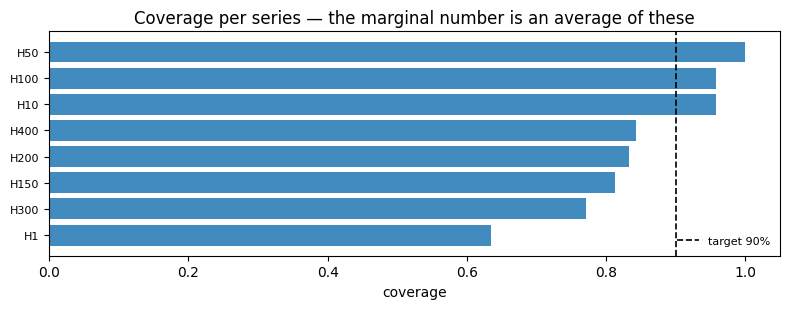

In [ ]:
order = np.argsort(per_series)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(np.arange(len(order)), per_series[order], color="C0", alpha=0.85)
ax.axvline(1 - ALPHA, color="k", lw=1.2, ls="--", label=f"target {1 - ALPHA:.0%}")
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([index.series_ids[i] for i in order], fontsize=8)
ax.set_xlabel("coverage")
ax.set_title("Coverage per series — the marginal number is an average of these")
ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.tight_layout()

A panel-level coverage figure is a weighted average of these bars, and this panel
shows why that matters: the 85.2% marginal figure averages `H1` at 63.5% with
`H50` at 100%, and five of the eight series sit below the 90% target. The
headline names none of them — which is why `coverage_by_series` exists, and why
the per-series calibration this page describes is worth its complexity.

## Next

- [NexCP](../methods/nexcp.html) — the method that reads the window axis as time.
- [Diagnostics](./diagnostics.html) — the rest of the per-slice measurements.
- [Architecture](../concepts/architecture.html) — the shape conventions in full.